# 5. Análisis bivariado (2.3)

Numéricas vs numéricas, categóricas vs numéricas, categóricas vs categóricas,
predictoras vs objetivo (incluida información mutua), matriz de correlación y
multicolinealidad (VIF). Con n ≈ 143.000 casi toda diferencia es significativa, así que
se reportan **tamaños de efecto** junto a los p-valores y se corrige por comparaciones
múltiples (**FDR de Benjamini-Hochberg**). Solo entrenamiento.

In [1]:
from pathlib import Path
import re, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

project_root = Path.cwd().resolve()
while not (project_root / "_config.yml").exists():
    if project_root.parent == project_root:
        raise FileNotFoundError("No se encontró _config.yml. Ejecuta el notebook dentro de la carpeta del libro.")
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

for _folder in ("tables", "figures"):          # se crean si no existen
    (project_root / _folder).mkdir(exist_ok=True)

from src.project_utils import *

configure_plots()
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 70)
TABLES = project_root / "tables"

def md_out(text):
    display(Markdown(text))

from scipy import stats
from sklearn.feature_selection import mutual_info_classif
train = load_train()
y = train[TARGET]
NUM = ["sales", "order_item_product_price", "order_item_quantity", "order_item_discount", "order_item_discount_rate",
       "order_item_profit_ratio", "benefit_per_order", "sales_per_customer", "days_shipping_scheduled",
       "items_in_order", "orders_prev_7d", "order_hour", "order_dow", "order_month", LAT, LON]
CAT = ["shipping_mode", "payment_type", "market", "order_region", "order_country", "customer_segment",
       "customer_country", "customer_state", "department_name", "category_name", "product_name", "order_weekend"]
folds = temporal_folds(train[DATE_COL])

## Numéricas vs numéricas

Correlaciones de Pearson (lineal) y Spearman (monótona), y diagramas *hexbin*
(n grande) para los pares más relacionados.

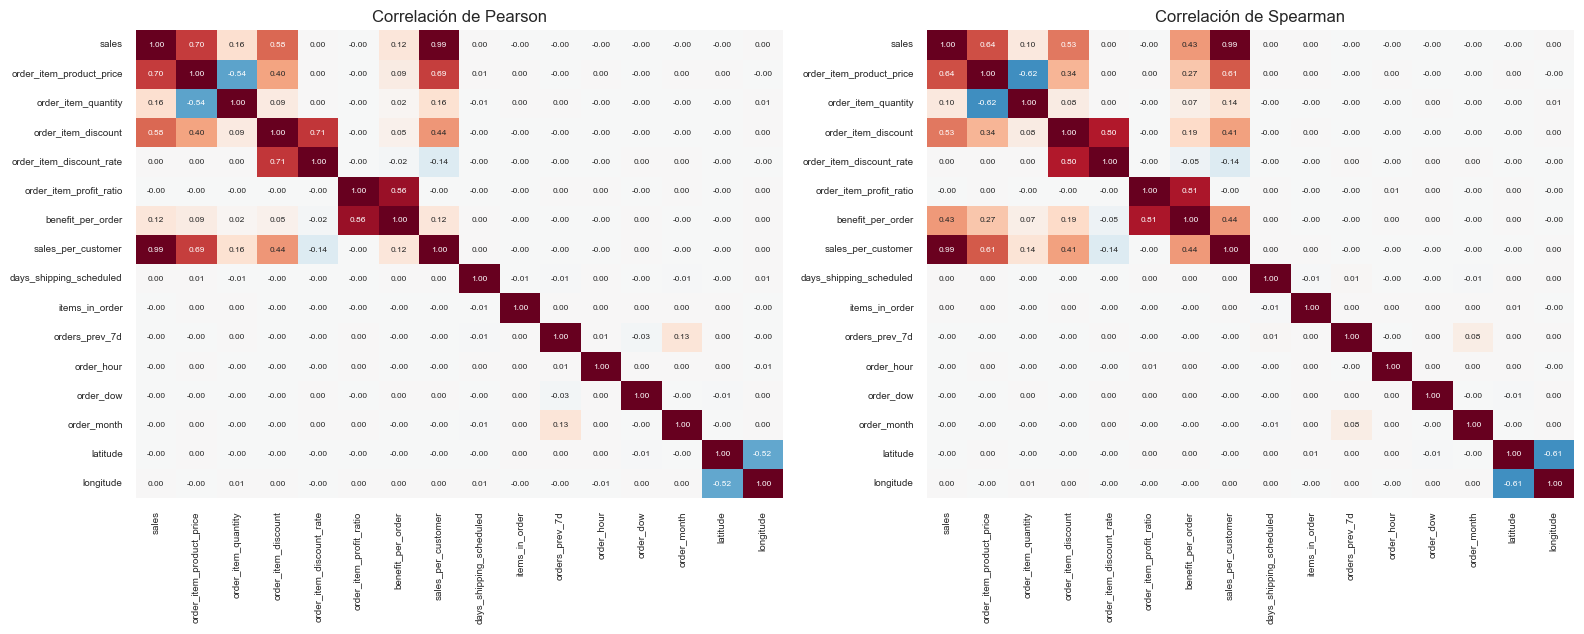

,var_1,var_2,pearson,spearman
6,sales,sales_per_customer,0.987,0.986
65,order_item_profit_ratio,benefit_per_order,0.861,0.813
42,order_item_discount,order_item_discount_rate,0.711,0.804
0,sales,order_item_product_price,0.700,0.643
15,order_item_product_price,order_item_quantity,-0.537,-0.623
20,order_item_product_price,sales_per_customer,0.691,0.614
119,latitude,longitude,-0.521,-0.611
2,sales,order_item_discount,0.577,0.525
75,benefit_per_order,sales_per_customer,0.124,0.437
5,sales,benefit_per_order,0.122,0.431


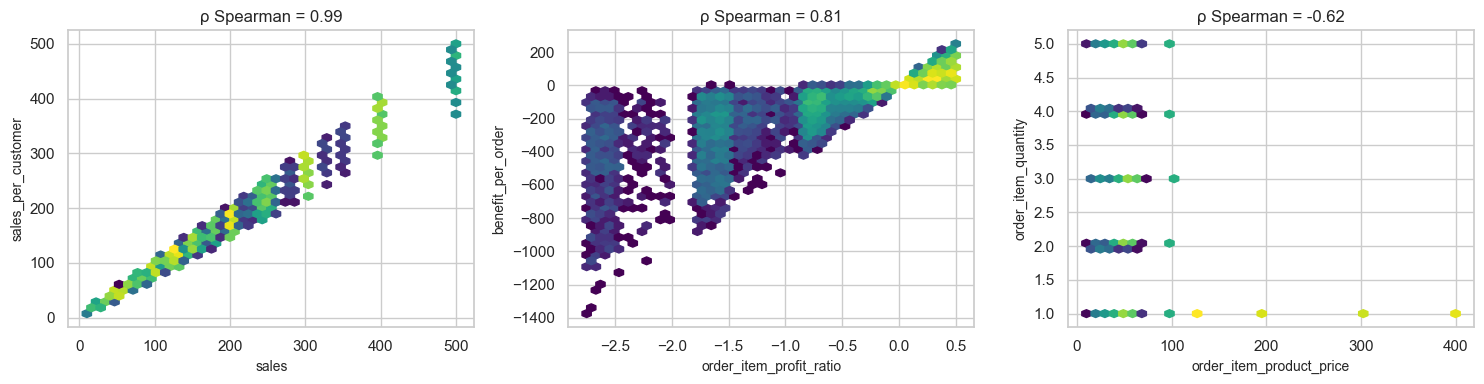

In [2]:
pear, spear = train[NUM].corr("pearson"), train[NUM].corr("spearman")
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, m, t in zip(axes, [pear, spear], ["Pearson", "Spearman"]):
    sns.heatmap(m, cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, annot=True, fmt=".2f", annot_kws={"size": 6}, cbar=False)
    ax.set_title(f"Correlación de {t}"); ax.tick_params(labelsize=7)
plt.tight_layout(); save_figure(fig, "05_correlaciones.png"); plt.show()

pares = []
for i, a in enumerate(NUM):
    for b in NUM[i + 1:]:
        pares.append({"var_1": a, "var_2": b, "pearson": pear.loc[a, b], "spearman": spear.loc[a, b]})
pares = pd.DataFrame(pares).assign(abs_s=lambda d: d["spearman"].abs()).sort_values("abs_s", ascending=False).drop(columns="abs_s")
pares.to_csv(TABLES / "correlaciones_pares.csv", index=False)
display(pares.head(10).round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (a, b) in zip(axes, [("sales", "sales_per_customer"), ("order_item_profit_ratio", "benefit_per_order"), ("order_item_product_price", "order_item_quantity")]):
    hb = ax.hexbin(train[a], train[b], gridsize=40, bins="log", cmap="viridis", mincnt=1)
    ax.set_xlabel(a); ax.set_ylabel(b); ax.set_title(f"ρ Spearman = {spear.loc[a, b]:.2f}")
plt.tight_layout(); save_figure(fig, "05_hexbin.png"); plt.show()

**Interpretación.** Hay tres bloques redundantes: (i) **ventas** (`sales`,
`sales_per_customer`, precio, descuento), (ii) **ganancia** (`benefit_per_order` y
`order_item_profit_ratio`, ρ ≈ 0,9) y (iii) precio vs cantidad (relación **negativa**: los
productos caros se compran de a uno). Las variables de calendario, carga y coordenadas
son prácticamente independientes del resto. Las relaciones no lineales (por ejemplo,
ganancia vs margen, que depende del monto) se ven en los hexbin.

## Categóricas vs numéricas y predictoras numéricas vs objetivo

Se comparan las distribuciones de cada numérica entre entregas tardías y no tardías
con **Mann-Whitney** (no paramétrica; las variables no son normales) y su tamaño de efecto
**rank-biserial** (|r| < 0,1 despreciable). Además, una categórica vs numérica clave:
el monto de venta según el modo de envío (**Kruskal-Wallis**, efecto ε²).

,variable,mediana_tardía,mediana_no_tardía,rank_biserial,p_valor,p_fdr,efecto
8,days_shipping_scheduled,2.0000,4.0000,-0.3955,0.0000,0.0000,mediano
11,order_hour,12.0000,11.0000,0.0561,0.0000,0.0000,despreciable
9,items_in_order,4.0000,4.0000,0.0060,0.0429,0.2289,despreciable
6,benefit_per_order,30.8900,31.2900,-0.0038,0.2125,0.7212,despreciable
13,order_month,6.0000,6.0000,0.0037,0.2254,0.7212,despreciable
1,order_item_product_price,59.9900,59.9900,-0.0028,0.3529,0.8458,despreciable
0,sales,179.9700,179.9700,-0.0021,0.4863,0.8458,despreciable
5,order_item_profit_ratio,0.2700,0.2700,-0.0019,0.5278,0.8458,despreciable
7,sales_per_customer,159.9900,159.9900,-0.0019,0.5368,0.8458,despreciable
12,order_dow,3.0000,3.0000,0.0018,0.5610,0.8458,despreciable


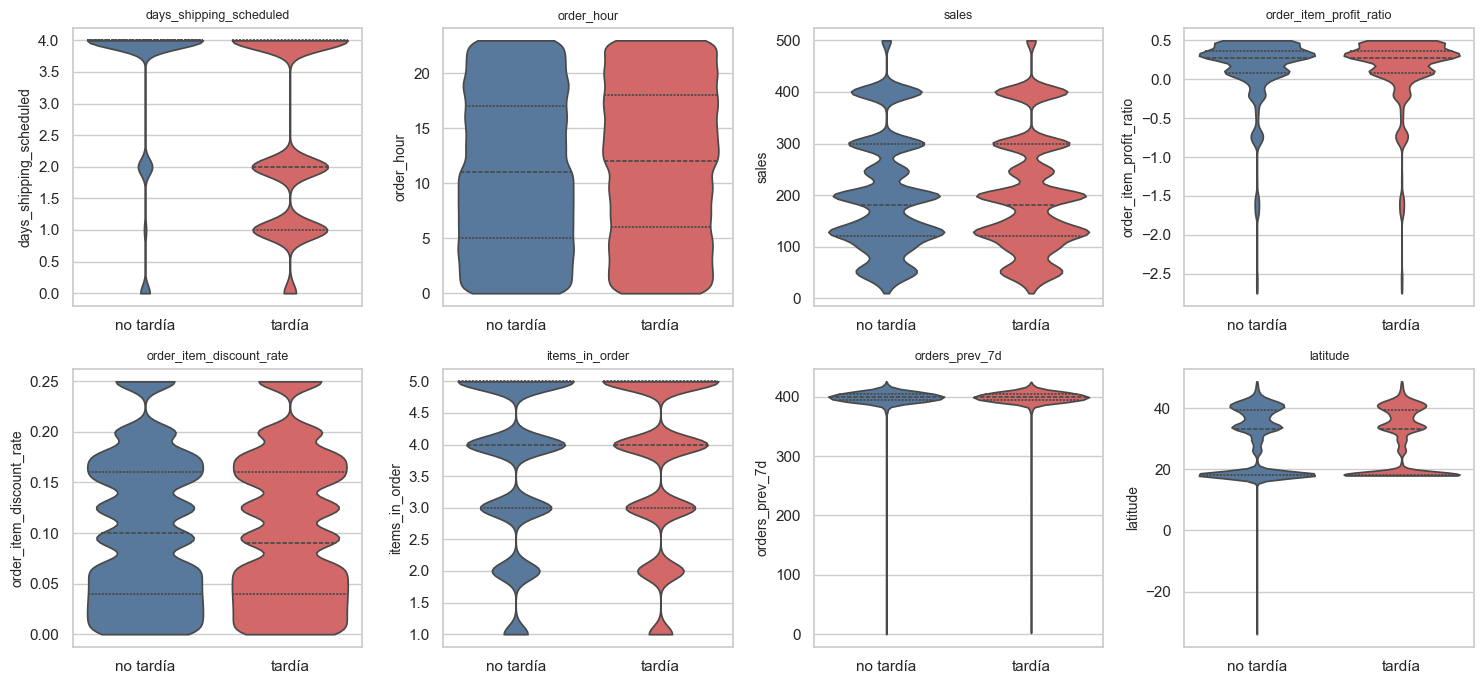

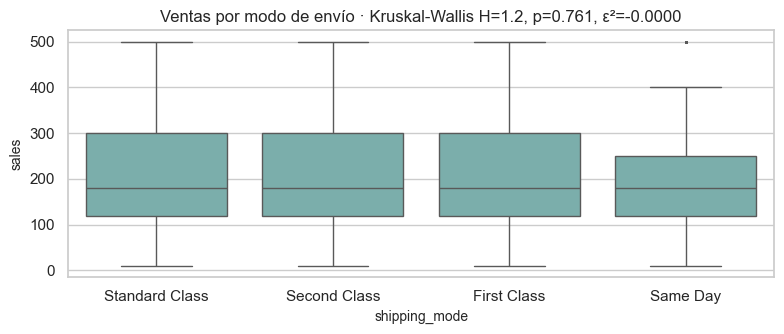

In [3]:
filas = []
for col in NUM:
    a, b = train.loc[y == 1, col], train.loc[y == 0, col]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    filas.append({"variable": col, "mediana_tardía": a.median(), "mediana_no_tardía": b.median(),
                  "rank_biserial": 2 * u / (len(a) * len(b)) - 1, "p_valor": p})
mw = pd.DataFrame(filas)
mw["p_fdr"] = fdr_bh(mw["p_valor"])
mw["efecto"] = pd.cut(mw["rank_biserial"].abs(), [-1, 0.1, 0.3, 0.5, 1], labels=["despreciable", "pequeño", "mediano", "grande"])
mw.to_csv(TABLES / "numericas_vs_objetivo.csv", index=False)
display(mw.sort_values("rank_biserial", key=abs, ascending=False).round(4))

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
sel = ["days_shipping_scheduled", "order_hour", "sales", "order_item_profit_ratio", "order_item_discount_rate", "items_in_order", "orders_prev_7d", LAT]
for ax, col in zip(axes.ravel(), sel):
    sns.violinplot(x=y.map({0: "no tardía", 1: "tardía"}), y=train[col], ax=ax, cut=0, inner="quartile",
                   hue=y.map({0: "no tardía", 1: "tardía"}), palette=["#4c78a8", "#e45756"], legend=False)
    ax.set_xlabel(""); ax.set_title(col, fontsize=9)
plt.tight_layout(); save_figure(fig, "05_violines.png"); plt.show()

g = [train.loc[train["shipping_mode"] == m, "sales"] for m in train["shipping_mode"].unique()]
h, pk = stats.kruskal(*g)
eps2 = (h - len(g) + 1) / (len(train) - len(g))
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.boxplot(data=train, x="shipping_mode", y="sales", ax=ax, color="#72b7b2", fliersize=1)
ax.set_title(f"Ventas por modo de envío · Kruskal-Wallis H={h:.1f}, p={pk:.3g}, ε²={eps2:.4f}")
plt.tight_layout(); save_figure(fig, "05_categorica_numerica.png"); plt.show()

**Interpretación.** Los p-valores son pequeños en varias variables, pero los
**tamaños de efecto** cuentan la historia real: solo `days_shipping_scheduled` tiene un
efecto apreciable (los envíos con más días programados —Standard— llegan tarde menos
veces); el resto de numéricas tiene |r| < 0,05. La hora del pedido muestra un efecto
pequeño (se explica en el cap. 7: es una hora de corte en Same Day). El monto de venta **no** depende del modo de envío (ε² ≈ 0): los clientes no
eligen el envío según el valor del pedido, de modo que no hay confusión entre ambos.

## Categóricas vs categóricas

Tablas de contingencia, prueba χ² y **V de Cramér** (con corrección de sesgo) entre
todos los pares de categóricas y con el objetivo.

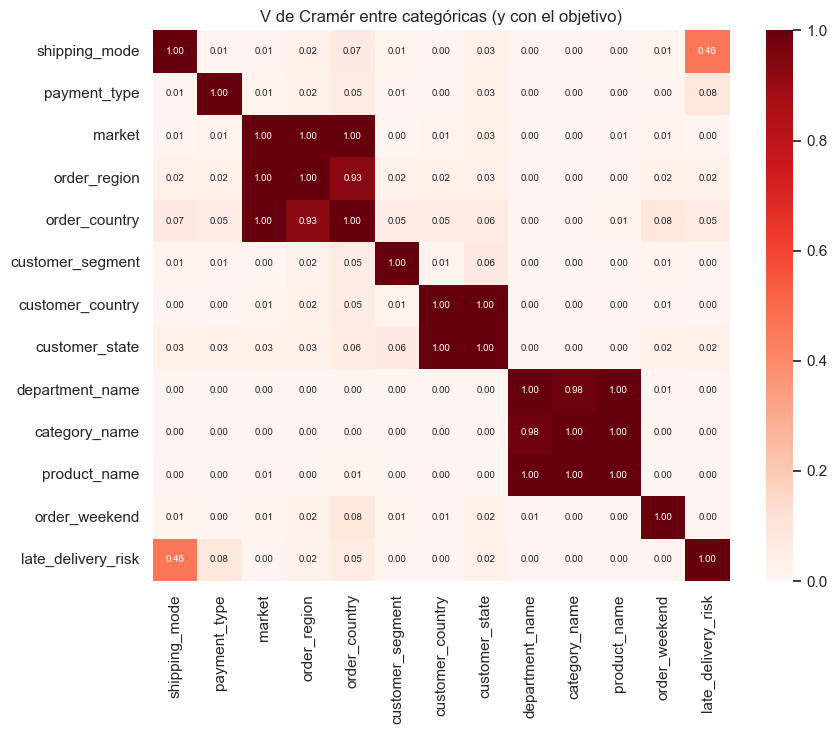

,var_1,var_2,V_cramer,chi2,p_valor,p_fdr
23,market,order_region,0.9999,5.723000e+05,0.0,0.0
72,category_name,product_name,0.9999,3.290725e+06,0.0,0.0
57,customer_country,customer_state,0.9999,1.430750e+05,0.0,0.0
69,department_name,product_name,0.9998,7.153750e+05,0.0,0.0
24,market,order_country,0.9994,5.723000e+05,0.0,0.0
68,department_name,category_name,0.9844,6.933248e+05,0.0,0.0
33,order_region,order_country,0.9288,2.718425e+06,0.0,0.0
11,shipping_mode,late_delivery_risk,0.4584,3.006947e+04,0.0,0.0
48,order_country,order_weekend,0.0808,1.097823e+03,0.0,0.0
22,payment_type,late_delivery_risk,0.0754,8.164063e+02,0.0,0.0


late_delivery_risk,0,1
shipping_mode,,
First Class,0.044,0.956
Same Day,0.552,0.448
Second Class,0.233,0.767
Standard Class,0.618,0.382
All,0.451,0.549


In [4]:
CATS_V = CAT + [TARGET]
V = pd.DataFrame(np.eye(len(CATS_V)), index=CATS_V, columns=CATS_V)
filas = []
for i, a in enumerate(CATS_V):
    for b in CATS_V[i + 1:]:
        v, chi2, p = cramers_v(train[a], train[b])
        V.loc[a, b] = V.loc[b, a] = v
        filas.append({"var_1": a, "var_2": b, "V_cramer": v, "chi2": chi2, "p_valor": p})
cram = pd.DataFrame(filas)
cram["p_fdr"] = fdr_bh(cram["p_valor"])
cram.to_csv(TABLES / "cramer_pares.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(V.astype(float), cmap="Reds", vmin=0, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("V de Cramér entre categóricas (y con el objetivo)")
plt.tight_layout(); save_figure(fig, "05_cramer.png"); plt.show()
display(cram.sort_values("V_cramer", ascending=False).head(12).round(4))
display(pd.crosstab(train["shipping_mode"], y, margins=True, normalize="index").round(3))

**Interpretación.** Las categóricas geográficas están **anidadas** (país → región →
mercado: V ≈ 1) y las de producto también (producto → categoría → departamento). Usar
todas a la vez sería redundante: se elige un nivel por jerarquía (cap. 10). Con el
objetivo, solo `shipping_mode` tiene una asociación relevante (V ≈ 0,4); el resto tiene
V < 0,05 aunque varias sean «significativas» tras FDR.

## Predictoras vs objetivo: información mutua y AUC univariado

La **información mutua** capta relaciones no lineales; el **AUC univariado** mide cuánto
separa cada variable por sí sola (0,5 = nada; 1 = perfecto). Las categóricas se
codifican con la tasa del objetivo calculada **fuera de pliegue** con los pliegues
temporales (sin fuga).

c:\Users\juand\miniconda3\envs\ml_venv\lib\site-packages\sklearn\metrics\cluster\_supervised.py:59: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)
c:\Users\juand\miniconda3\envs\ml_venv\lib\site-packages\sklearn\metrics\cluster\_supervised.py:59: UserWarning: Clustering metrics expects discrete values but received continuous values for label, and binary values for target
  warnings.warn(msg, UserWarning)


,variable,tipo,información_mutua,AUC univariado
0,shipping_mode,categórica,0.1206,0.7265
1,days_shipping_scheduled,numérica,0.1206,0.6978
2,payment_type,categórica,0.0021,0.5323
3,order_hour,numérica,0.0021,0.5280
4,customer_country,categórica,0.0000,0.5062
5,customer_segment,categórica,0.0000,0.5033
6,items_in_order,numérica,0.0001,0.5030
7,order_weekend,categórica,0.0000,0.5027
8,customer_state,categórica,0.0006,0.5025
9,department_name,categórica,0.0000,0.5024


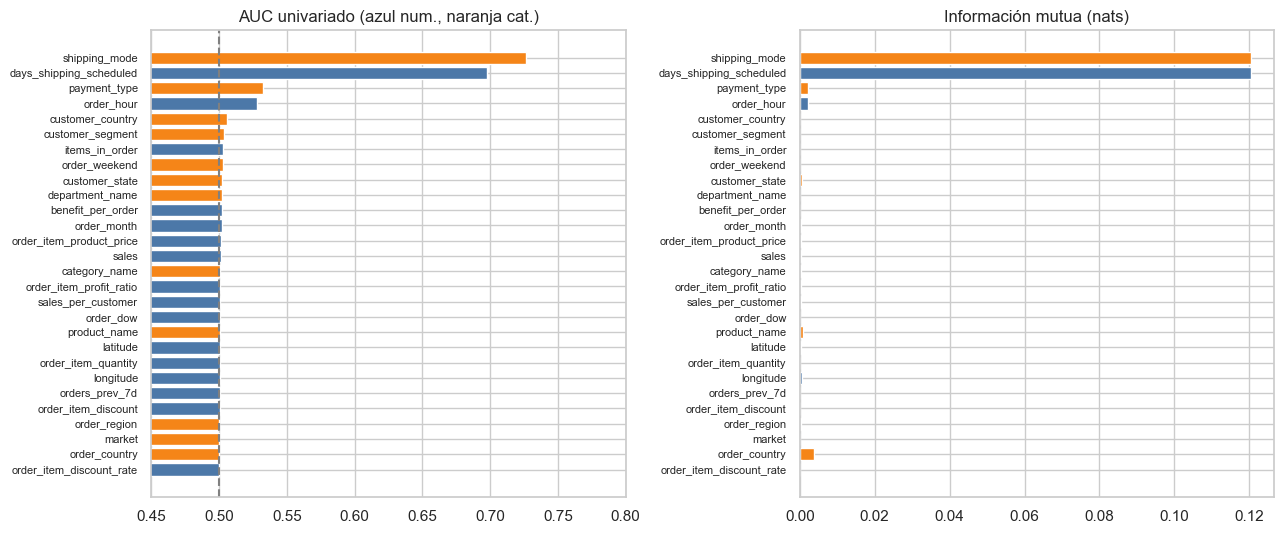

In [5]:
rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(len(train), 40000, replace=False)
# Las numéricas se discretizan en (hasta) 20 cuantiles: el estimador k-NN de información mutua se sesga
# cuando hay muchos valores repetidos (precios, coordenadas de una misma ciudad).
Xmi = pd.DataFrame({c: (train[c].iloc[idx] if train[c].nunique() <= 30
                        else pd.qcut(train[c].iloc[idx], 20, labels=False, duplicates="drop")) for c in NUM})
mi_num = mutual_info_classif(Xmi, y.iloc[idx], discrete_features=True, random_state=RANDOM_STATE)
Xc = pd.DataFrame({c: pd.factorize(train[c].iloc[idx].astype(str))[0] for c in CAT})
mi_cat = mutual_info_classif(Xc, y.iloc[idx], discrete_features=True, random_state=RANDOM_STATE)
rank = pd.DataFrame({"variable": NUM + CAT, "tipo": ["numérica"] * len(NUM) + ["categórica"] * len(CAT),
                     "información_mutua": np.r_[mi_num, mi_cat]})
rank["AUC univariado"] = [univariate_auc(train[c], y) if t == "numérica" else categorical_auc_oof(train[c], y, folds)
                          for c, t in zip(rank["variable"], rank["tipo"])]
rank = rank.sort_values("AUC univariado", ascending=False).reset_index(drop=True)
rank.to_csv(TABLES / "ranking_univariado.csv", index=False)
display(rank.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
r = rank.iloc[::-1]
axes[0].barh(r["variable"], r["AUC univariado"], color=np.where(r["tipo"] == "numérica", "#4c78a8", "#f58518"))
axes[0].axvline(0.5, color="gray", ls="--"); axes[0].set_xlim(0.45, 0.8); axes[0].set_title("AUC univariado (azul num., naranja cat.)")
axes[1].barh(r["variable"], r["información_mutua"], color=np.where(r["tipo"] == "numérica", "#4c78a8", "#f58518"))
axes[1].set_title("Información mutua (nats)")
for ax in axes: ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); save_figure(fig, "05_ranking_univariado.png"); plt.show()

## Multicolinealidad (VIF)

In [6]:
vif = pd.DataFrame({"variable": NUM, "VIF": variance_inflation_factors(train[NUM].to_numpy())}).sort_values("VIF", ascending=False)
vif.to_csv(TABLES / "vif_numericas.csv", index=False)
display(vif.round(2))
NUM_RED = [c for c in NUM if c not in ("sales_per_customer", "benefit_per_order", "order_item_discount", "days_shipping_scheduled")]
vif2 = pd.DataFrame({"variable": NUM_RED, "VIF": variance_inflation_factors(train[NUM_RED].to_numpy())}).sort_values("VIF", ascending=False)
vif2.to_csv(TABLES / "vif_numericas_reducido.csv", index=False)
NUM_RED2 = [c for c in NUM_RED if c != "order_item_product_price"]
vif3 = variance_inflation_factors(train[NUM_RED2].to_numpy())
md_out(f"Tras quitar las columnas redundantes (copias de ventas/ganancia/descuento y los días programados, equivalentes a `shipping_mode`), "
       f"el VIF máximo baja a **{es(vif2['VIF'].max(), 2)}** ({vif2.iloc[0]['variable']}), porque `sales` = precio × cantidad. "
       f"Si además se omite el precio (su información queda en ventas y cantidad), el VIF máximo es **{es(vif3.max(), 2)}**.")
display(vif2.round(2))

,variable,VIF
0,sales,5.735459e+09
7,sales_per_customer,4.749347e+09
3,order_item_discount,1.770601e+08
1,order_item_product_price,1.234000e+01
2,order_item_quantity,6.450000e+00
6,benefit_per_order,4.130000e+00
4,order_item_discount_rate,4.130000e+00
5,order_item_profit_ratio,4.070000e+00
14,latitude,1.370000e+00
15,longitude,1.370000e+00


Tras quitar las columnas redundantes (copias de ventas/ganancia/descuento y los días programados, equivalentes a `shipping_mode`), el VIF máximo baja a **12,31** (order_item_product_price), porque `sales` = precio × cantidad. Si además se omite el precio (su información queda en ventas y cantidad), el VIF máximo es **1,37**.

,variable,VIF
1,order_item_product_price,12.31
0,sales,8.99
2,order_item_quantity,6.43
10,latitude,1.37
11,longitude,1.37
6,orders_prev_7d,1.02
9,order_month,1.02
8,order_dow,1.00
7,order_hour,1.00
5,items_in_order,1.00


**Interpretación y selección preliminar de variables.**

- **Patrón dominante:** `shipping_mode` (y su equivalente `days_shipping_scheduled`) es la
  única predictora con señal sustancial (AUC ≈ 0,73). Le siguen, muy lejos, `payment_type`
  y la **hora del pedido** (AUC ≈ 0,53); el resto está en 0,50–0,51.
- **Alerta sobre `payment_type`:** su asociación con el objetivo (V ≈ 0,08) no se debe a que
  un medio de pago retrase envíos, sino a que los pedidos **cancelados o sospechosos de
  fraude** (etiqueta 0 por construcción) se concentran en un medio de pago. Se analiza en
  el capítulo 9.
- **Relaciones no lineales e interacciones:** el efecto de la hora no es lineal ni general;
  el capítulo 7 muestra que se concentra en los envíos Same Day (hora de corte del mediodía)
  → interacción modo × jornada y componentes cíclicos seno/coseno.
- **Multicolinealidad:** VIF enormes entre ventas, total y descuento (combinaciones
  aritméticas) y VIF > 10 del precio, explicado por ventas × cantidad.
- **Selección preliminar** (se formaliza en el cap. 10): `shipping_mode` (no los días
  programados), `payment_type`, `customer_segment`, `market`, `order_region`,
  `order_country` (con agrupación de raras), `department_name`, `category_name`;
  numéricas no redundantes: `sales`, `order_item_quantity`, `order_item_discount_rate`,
  `order_item_profit_ratio`, `items_in_order`, `orders_prev_7d` y calendario cíclico.
  Las coordenadas se evalúan en el capítulo 8.